In [21]:
import xgboost

# Imports needed to run
import importlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SMALL_SIZE = 14
MEDIUM_SIZE = 16
BIGGER_SIZE = 18

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, roc_auc_score, auc, accuracy_score, log_loss

import torch
import torch.nn
import torch.optim
import torch.utils.data
import time

random=False

# Using LCU functions; load_random_data & load_SUSY_data
def load_random_data():
    # array of means and widths for gaussians,
    # indices are:
    # - number of dimensions
    # - signal (0) vs background (1)
    # - mean (0) vs width (1)

    N=20000 # number of points
    m=10 # dimensions
    
    np.random.seed(123)
    width_scale_factor=2.
    mean_scale_factor=1.
    
    # if we want more control over the function, for example
    means_widths=[[[4,0.4],
                   [-2,.10]],
                  [[3,1.0],
                   [-1,0.5]]]
    
    means_widths=np.random.randn(m,2,2)               
    
    # now construct the training data.  after taking transpose, should be N rows by m columns.  
    x_signal=np.array([mean_scale_factor*means_widths[i][0][0]+width_scale_factor*np.fabs(means_widths[i][0][1])*np.random.randn(N) for i in range(m)]).T
    y_signal=np.ones(N)
    x_backgr=np.array([mean_scale_factor*means_widths[i][1][0]+width_scale_factor*np.fabs(means_widths[i][1][1])*np.random.randn(N) for i in range(m)]).T
    y_backgr=np.zeros(N)

    return x_signal, y_signal, x_backgr, y_backgr, [f"Feature {b}" for b in range(m)]


def load_SUSY_data():
    # Prep Data using Pandas
    x_sig_data=None
    y_sig_data=None
    
    x_bkg_data=None
    y_bkg_data=None
    
    num_sig_events=0
    num_bkg_events=0
    
    # Need to copy the last branch, Rll, so that we have a total of 5 branches
    branches=[
        'lep1MT_Met','lep1_DPhiMet',
        'lep2MT_Met','lep2_DPhiMet',
        'jet0Pt','Rll','met_Et',
    #    ,'lep1Pt','lep2Pt',
    #    ,'lep1Eta','lep1Phi', 
    #    ,'lep2Eta','lep2Phi'
    #    ,'met_Phi'
    #    'nJet30','mt2leplsp_100'
    ]
    
    # open signal
    mass=200
    split=30
    filepath='/data/mhance/SUSY/Compressed/'
    filebase='SusySkimSlep_v0.2_SlepSignals__'
    filename='MGPy8EG_A14N23LO_SlepSlep_dir_2L2MET75_%dp0_%dp0_NoSys' % (mass,mass-split)
    filesuff='.hf5'
    
    # Makes data frame for signal events
    fullname=filepath+filebase+filename+filesuff
    df = pd.read_hdf(fullname, key=filename)
    mask = (df['lep1Pt']>10) & (df['lep2Pt']>10) & (df['nBJet30']==0) & (df['met_Et']>300) & (df['minDPhiAllJetsMet']>0.4)
    df = df[mask]
    df1 = df[branches].to_numpy()
    num_sig_events = len(df1)
    x_signal = df1
    y_signal = np.ones(num_sig_events)
    #print("Extracted %7d signal events" % num_sig_events)

    # Now background
    fullname=filepath+"SusySkimSlep_v0.2_diboson2L__diboson2L_NoSys"+filesuff
    df = pd.read_hdf(fullname, key='diboson2L_NoSys')
    mask = (df['lep1Pt']>10) & (df['lep2Pt']>10) & (df['nBJet30']==0) & (df['met_Et']>300) & (df['minDPhiAllJetsMet']>0.4)
    df = df[mask]
    df2 = df[branches].to_numpy()
    num_bkg_events = len(df2)
    x_backgr = df2
    y_backgr=np.zeros(num_bkg_events)
    #print("Extracted %7d background events" % num_bkg_events)    

    return x_signal, y_signal, x_backgr, y_backgr, branches
    
def concatenating(xSig, ySig, xBack, yBack):
    return np.concatenate((xSig, xBack)), np.concatenate((ySig, yBack))


def plotting_features(signal, background, branches, m):
    plotsacross=5 if (m==10) else 4
    
    fig = plt.figure(figsize=(20,2.5*(int(m/plotsacross)+1)))
    fig.tight_layout()
    nbins=50
    
    for b in range(m):
        ax=fig.add_subplot(int(m/plotsacross)+1,plotsacross,1+b)
        plt.subplots_adjust(hspace=0.5,wspace=0.5)
        plt.yscale('log')
        ax.hist(signal[:,b],nbins,density=True,histtype='stepfilled',alpha=0.5,color='red')
        ax.hist(background[:,b],nbins,density=True,histtype='stepfilled',alpha=0.5,color='blue')
        ax.set_xlabel(f"{branches[b]}")
        ax.set_ylabel("Events/Bin")

In [22]:
x_signal, y_signal, x_backgr, y_backgr, branches = load_random_data() if random else load_SUSY_data()

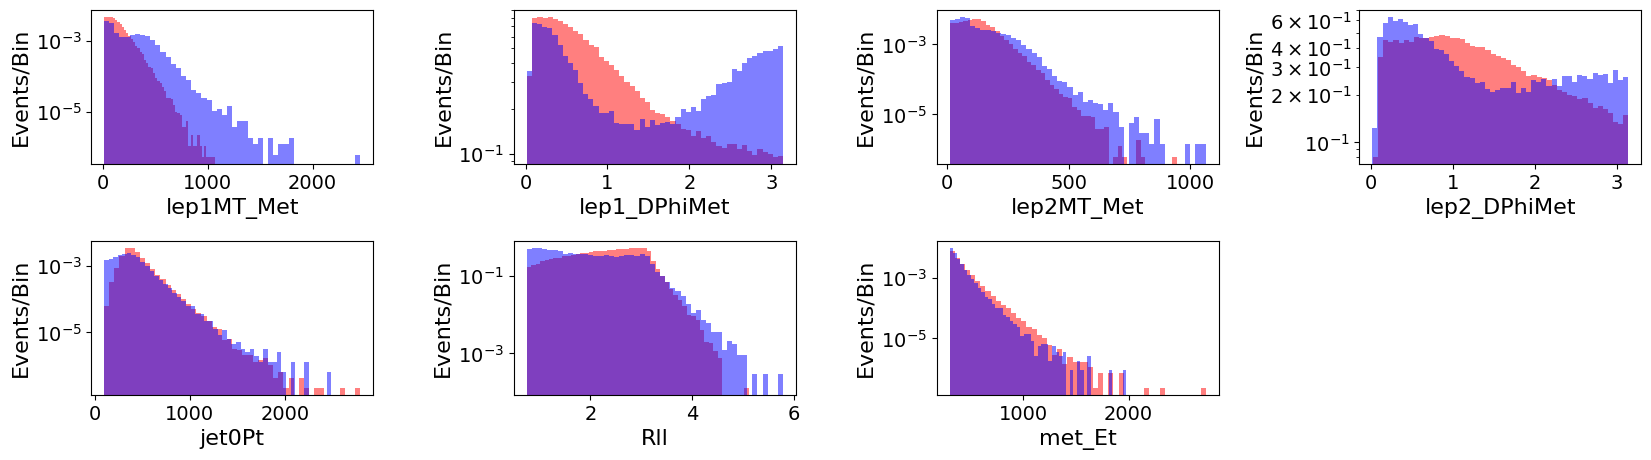

In [23]:
m = len(branches)
plotting_features(x_signal, x_backgr, branches, m)

In [24]:
x, y = concatenating(x_signal, y_signal, x_backgr, y_backgr)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)
sc = StandardScaler()
x_train_scaled = sc.fit_transform(x_train)
x_test_scaled  = sc.transform(x_test)

In [25]:
models={}
for nest in range(500,1000,500):
    models[nest]={}
    print("--------------------------")
    for maxd in range(2,5):

        models[nest][maxd] = xgboost.XGBClassifier(
            objective='binary:logistic',
            eval_metric='logloss',
            n_estimators=nest,
            max_depth=maxd,
            learning_rate=0.1
        )
        
        # 4. Train the model
        models[nest][maxd].fit(x_train_scaled, y_train)

        # quick check
        y_pred_test       = models[nest][maxd].predict      (x_test_scaled)
        y_pred_proba_test = models[nest][maxd].predict_proba(x_test_scaled)
        y_pred_train      = models[nest][maxd].predict      (x_train_scaled)
        y_pred_proba_train= models[nest][maxd].predict_proba(x_train_scaled)  
        
        ll_train = log_loss(y_train, y_pred_proba_train)
        ll_test  = log_loss(y_test , y_pred_proba_test )
        

        accuracy = accuracy_score(y_test, y_pred_test)
        print(f"Done with {nest:5d} {maxd:2d}.  Test accuracy = {accuracy:.3f}.  ll_train = {ll_train:.3f}, ll_test = {ll_test:.3f}")
print("--------------------------")

--------------------------
Done with   500  2.  Test accuracy = 0.829.  ll_train = 0.406, ll_test = 0.408
Done with   500  3.  Test accuracy = 0.835.  ll_train = 0.384, ll_test = 0.394
Done with   500  4.  Test accuracy = 0.840.  ll_train = 0.363, ll_test = 0.387
--------------------------


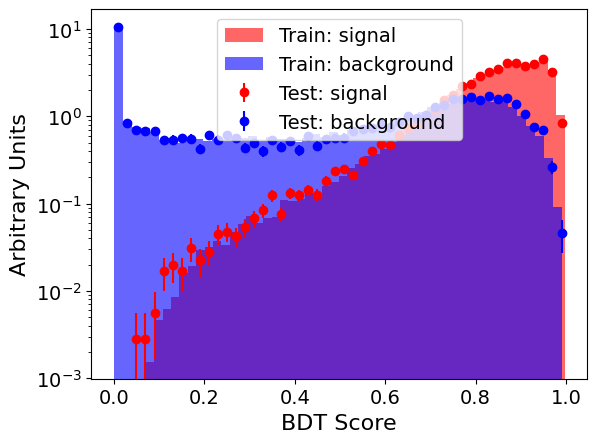

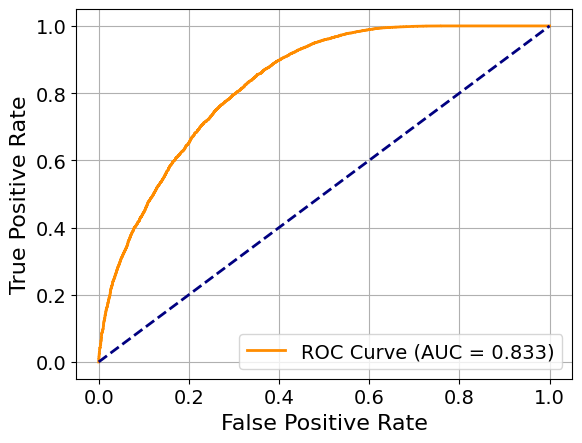

In [26]:
model=models[500][3]

y_score_test  = model.predict_proba(x_test_scaled)[:, 1]
y_score_train = model.predict_proba(x_train_scaled)[:, 1]


def ListToGraph(l,bins,color,low=0,high=1,weight=0,label=""):
    counts,bin_edges = np.histogram(l,bins,range=(low,high))
    bin_centres = (bin_edges[:-1] + bin_edges[1:])/2.
    err = np.sqrt(counts)
    if weight==0:
        weight=1./(sum(counts)*(bin_edges[1]-bin_edges[0]))
    counts = weight*counts
    err = weight*err
    return plt.errorbar(bin_centres, counts, yerr=err, fmt='o',color=color,label=label)


# Plot BDT score distributions
#plt.figure(figsize=(8, 5))
plt.hist(y_score_train[y_train == 1], bins=50, alpha=0.6, label="Train: signal", color='red', density=True)
plt.hist(y_score_train[y_train == 0], bins=50, alpha=0.6, label="Train: background", color='blue', density=True)

signal_test=ListToGraph(y_score_test[y_test == 1],50,"red",0,1, label="Test: signal")
backgr_test=ListToGraph(y_score_test[y_test == 0],50,"blue",0,1, label="Test: background")


plt.xlabel("BDT Score")
plt.ylabel("Arbitrary Units")
plt.legend(loc="upper center")
#plt.title("BDT Output Score")
#plt.grid(True)
#plt.tight_layout()
plt.yscale("log")
plt.show()

# --- Step 4: ROC Curve ---
fpr, tpr, thresholds = roc_curve(y_test, y_score_test)
roc_auc = auc(fpr, tpr)

#plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
#plt.title("Receiver Operating Characteristic")
plt.legend(loc="lower right")
plt.grid(True)
#plt.tight_layout()
plt.show()

In [27]:
import pickle
with open(f'cabin/cabin-notebooks/ROCs/{"random" if random else "SUSY"}/bdt_fpr.pkl', 'wb') as f:
    pickle.dump(fpr, f)
with open(f'cabin/cabin-notebooks/ROCs/{"random" if random else "SUSY"}/bdt_tpr.pkl', 'wb') as f:
    pickle.dump(tpr, f)